# DSA 2050A — Week 9 practical GROUP lab
## Model selection and defensible evaluation | Python + GitHub

**Work in your existing course groups.** Build one collaborative project and submit one shared GitHub repository link per group. List all member names, IDs and contributions in `README.md`.

**Case:** A fictional Kenyan internet provider wants to identify customers at risk of churn.
**Your group’s task:** Compare models fairly, investigate failures, document your decision, and evaluate the final test only after freezing the choice.

**Important:** Data is **synthetic for teaching**. `cancellation_confirmed` is known only *after* the outcome and is a deliberate leakage trap. Do not model using it.

**Before starting:** Open the `DSA2050_Week9_GitHub_Lab` folder in VS Code, select your Python environment, then run cells **from top to bottom**. Install packages using `python -m pip install -r requirements.txt` from the VS Code Terminal.

### Step 1 — Confirm environment and locate the datasets
**Click path:** VS Code → File → Open Folder → project folder → `notebooks/Week9_Model_Selection_Lab.ipynb` → **Select Kernel** (top right) → Python environment → **Run** each cell.

**Group discussion:** Why must the final test not be consulted before choosing a model? Add your explanation below.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance
import sklearn

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA = ROOT / 'data'
REPORTS = ROOT / 'reports'
REPORTS.mkdir(parents=True, exist_ok=True)
assert (DATA / 'churn_development.csv').exists(), 'Open the project folder in VS Code.'
print('Project:', ROOT.resolve())
print('Python:', sys.version.split()[0], 'scikit-learn:', sklearn.__version__)

Project: C:\Users\admin\Downloads\DSA2050_Week9_GitHub_Lab
Python: 3.12.5 scikit-learn: 1.9.1


### Step 2 — Open **development data only**, inspect, and remove leakage
Do **not** read `churn_final_test.csv` yet. Your prediction-time features must be available *before cancellation*.

In [2]:
dev = pd.read_csv(DATA / 'churn_development.csv')
print('Shape:', dev.shape)
print('Churn rate:', round(dev['churn'].mean(), 3))
print('Missing values:\n', dev.isna().sum())
display(dev.head())

TARGET = 'churn'
LEAKAGE_OR_IDS = ['churn', 'customer_id', 'cancellation_confirmed']
X_dev = dev.drop(columns=LEAKAGE_OR_IDS)
y_dev = dev[TARGET].astype(int)
print('Allowed features:', X_dev.columns.tolist())
assert 'cancellation_confirmed' not in X_dev.columns
assert 'customer_id' not in X_dev.columns

Shape: (2720, 11)
Churn rate: 0.335
Missing values:
 customer_id                 0
tenure_months               0
monthly_charges_kes       156
support_tickets_90d       120
service_calls_90d           0
plan_type                   0
region                     93
autopay                     0
customer_segment            0
cancellation_confirmed      0
churn                       0
dtype: int64


,customer_id,tenure_months,monthly_charges_kes,support_tickets_90d,service_calls_90d,plan_type,region,autopay,customer_segment,cancellation_confirmed,churn
0,CUST-12486,22,1943.94,1.0,2,Basic,Mombasa,Yes,Established,Active,0
1,CUST-12546,40,5003.13,1.0,0,Premium,Nairobi,No,Established,Active,0
2,CUST-11112,57,2796.23,1.0,1,Basic,Nairobi,Yes,Established,Active,0
3,CUST-12753,33,4697.39,NaN,0,Premium,Nairobi,Yes,Established,Active,0
4,CUST-10753,53,4330.27,2.0,1,Standard,Mombasa,No,Established,Active,0


Allowed features: ['tenure_months', 'monthly_charges_kes', 'support_tickets_90d', 'service_calls_90d', 'plan_type', 'region', 'autopay', 'customer_segment']


**Write:** Identify (a) the target, (b) the unit of analysis, (c) the leakage column, and (d) why customer ID should not be used as a predictor.

a) Target: churn. It is the dependent variable the model aims to predict, indicating whether a customer has churned (1) or not churned (0).

(b) Unit of analysis: An individual customer. Each row represents one customer and contains their subscription, service usage, payment, and customer-segment information.

(c) Leakage column: cancellation_confirmed. It is excluded because it may reveal that a customer has already cancelled, giving the model information about the outcome it is supposed to predict. Including it could lead to data leakage and misleadingly high evaluation performance.

(d) Customer ID: customer_id is a unique identifier used to distinguish customers, not a meaningful measure of customer behaviour. Using it as a predictor could cause the model to learn arbitrary patterns associated with identifiers rather than genuine relationships with churn.

### Step 3 — Create leakage-safe preprocessing pipelines
**Analogy:** In each practice exam (CV fold), students should learn imputation values and scaling from the *practice questions* alone—not from the hidden answer sheet. The `Pipeline` re-fits preprocessing within each fold.

In [3]:
num_cols = X_dev.select_dtypes(include='number').columns.tolist()
cat_cols = X_dev.select_dtypes(exclude='number').columns.tolist()

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
category_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', category_pipe, cat_cols)
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Numeric:', num_cols)
print('Categorical:', cat_cols)
print('Same fixed CV:', cv)

Numeric: ['tenure_months', 'monthly_charges_kes', 'support_tickets_90d', 'service_calls_90d']
Categorical: ['plan_type', 'region', 'autopay', 'customer_segment']
Same fixed CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


### Step 4 — Establish a naive baseline
A **DummyClassifier** predicts based on a simple rule. It tells you what success without a real model looks like.

**Predict first:** Will a majority-class model have high accuracy if most customers stay, even when it never catches churn?

Yes. The majority-class model will achieve approximately 66.5% accuracy because it predicts every customer as a non-churner, correctly classifying the majority of customers. However, it will fail to identify any customers who churn.

In [4]:
dummy_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent'))
])
metrics = {'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}
baseline_scores = cross_validate(dummy_pipe, X_dev, y_dev, cv=cv, scoring=metrics)
print('Baseline fold F1:', np.round(baseline_scores['test_f1'], 3))
print('Baseline mean F1:', round(baseline_scores['test_f1'].mean(), 3))

c:\Users\admin\Downloads\DSA2050_Week9_GitHub_Lab\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\admin\Downloads\DSA2050_Week9_GitHub_Lab\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\admin\Downloads\DSA2050_Week9_GitHub_Lab\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

Baseline fold F1: [0. 0. 0. 0. 0.]
Baseline mean F1: 0.0


c:\Users\admin\Downloads\DSA2050_Week9_GitHub_Lab\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### Step 5 — Compare two candidates using identical CV folds
Logistic regression is usually stable and interpretable. A decision tree learns if/then rules but can overfit. For each, search **three understandable settings**, not hundreds.

**Primary selection metric: F1** (balances precision and recall). Report precision and recall as secondary metrics.



Logistic regression and decision tree will be compared using the same five stratified cross-validation folds to ensure a fair evaluation. F1-score will be the primary selection metric, while precision and recall will serve as secondary metrics. The model with the best F1-score will be preferred, without changing the selection metric after reviewing the results.

In [5]:
candidates = {
    'Logistic regression': (
        LogisticRegression(max_iter=2000, random_state=42),
        {'model__C': [0.1, 1, 10]}
    ),
    'Decision tree': (
        DecisionTreeClassifier(random_state=42),
        {'model__max_depth': [3, 5, 8]}
    )
}
searches = {}
logs = []
for name, (model, grid) in candidates.items():
    pipeline = Pipeline([('prep', preprocessor), ('model', model)])
    search = GridSearchCV(
        pipeline, grid, cv=cv, scoring=metrics,
        refit='f1', n_jobs=1, return_train_score=True
    )
    search.fit(X_dev, y_dev)
    searches[name] = search
    results = pd.DataFrame(search.cv_results_)
    for _, r in results.iterrows():
        row = {
            'model': name, 'settings': str(r['params']),
            'mean_f1': float(r['mean_test_f1']),
            'std_f1': float(r['std_test_f1']),
            'mean_precision': float(r['mean_test_precision']),
            'mean_recall': float(r['mean_test_recall'])
        }
        for i in range(5):
            row[f'fold_{i+1}_f1'] = float(r[f'split{i}_test_f1'])
        logs.append(row)

experiment_log = pd.DataFrame(logs).sort_values('mean_f1', ascending=False)
experiment_log.to_csv(REPORTS / 'experiment_log.csv', index=False)
display(experiment_log.round(3))
print('Saved:', REPORTS / 'experiment_log.csv')

,model,settings,mean_f1,std_f1,mean_precision,mean_recall,fold_1_f1,fold_2_f1,fold_3_f1,fold_4_f1,fold_5_f1
1,Logistic regression,{'model__C': 1},0.470,0.053,0.624,0.378,0.391,0.534,0.472,0.434,0.519
2,Logistic regression,{'model__C': 10},0.470,0.053,0.624,0.378,0.391,0.534,0.472,0.434,0.519
0,Logistic regression,{'model__C': 0.1},0.465,0.054,0.625,0.371,0.388,0.533,0.454,0.432,0.519
3,Decision tree,{'model__max_depth': 3},0.398,0.049,0.566,0.318,0.392,0.457,0.316,0.437,0.391
4,Decision tree,{'model__max_depth': 5},0.382,0.023,0.583,0.287,0.376,0.383,0.365,0.362,0.426
5,Decision tree,{'model__max_depth': 8},0.372,0.051,0.495,0.300,0.298,0.439,0.338,0.370,0.417


Saved: c:\Users\admin\Downloads\DSA2050_Week9_GitHub_Lab\reports\experiment_log.csv


Logistic Regression achieved the highest mean F1-score of 0.470 with C=1 and C=10, outperforming all three Decision Tree configurations. Its relatively consistent cross-validation performance (standard deviation of 0.053) and higher precision and recall indicate a better balance between identifying churn customers and limiting incorrect predictions. Therefore, Logistic Regression is the preferred candidate for further evaluation.

### Step 6 — Examine score variation and select a candidate
Two models may have similar mean F1 but different fold stability. Larger `std_f1` means the validation score changed more across folds.

**Group task:** Compare the best logistic regression and best tree, then choose one. You **may** override the automatic highest-F1 default if you provide a defensible reason. Preserve the selected model's tuned hyperparameters.

Logistic Regression is selected because it achieved a higher mean F1-score (0.470) than the best Decision Tree (0.398). Its standard deviation of 0.053 indicates reasonably consistent performance across the five validation folds. It also achieved higher precision (0.624) and recall (0.470), providing a better balance in identifying customers likely to churn. Therefore, Logistic Regression with C=1 is selected for further evaluation

In [6]:
best_by_model = (experiment_log.sort_values('mean_f1', ascending=False)
                 .drop_duplicates(subset='model').reset_index(drop=True))
display(best_by_model[['model','mean_f1','std_f1','mean_recall','mean_precision']].round(3))

# Change only if your explanation supports the different choice.
CHOSEN_MODEL = best_by_model.iloc[0]['model']
assert CHOSEN_MODEL in searches
chosen_search = searches[CHOSEN_MODEL]
chosen_pipeline = chosen_search.best_estimator_
print('Chosen:', CHOSEN_MODEL)
print('Settings:', chosen_search.best_params_)
print('Development CV F1:', round(chosen_search.best_score_, 3))

,model,mean_f1,std_f1,mean_recall,mean_precision
0,Logistic regression,0.470,0.053,0.378,0.624
1,Decision tree,0.398,0.049,0.318,0.566


Chosen: Logistic regression
Settings: {'model__C': 1}
Development CV F1: 0.47


Logistic Regression was selected because it achieved a higher mean F1-score (0.470) than the Decision Tree (0.398). It also recorded higher mean precision (0.624) and recall (0.378), indicating better overall performance in identifying customers likely to churn. Although its F1 standard deviation (0.053) was slightly higher than that of the Decision Tree (0.049), the difference is small. Logistic Regression with C=1 was therefore selected for further evaluation.

### Step 7 — Out-of-fold errors and subgroup analysis
`cross_val_predict` makes each development-row prediction from a model trained on **other folds**. Use these to inspect false positives (flagged churn that did not happen) and false negatives (missed churn).

**Caution:** Out-of-fold diagnostics use the same development dataset involved in selection; do not call them an untouched final-test estimate.

              precision    recall  f1-score   support

           0       0.74      0.89      0.81      1810
           1       0.63      0.38      0.47       910

    accuracy                           0.72      2720
   macro avg       0.68      0.63      0.64      2720
weighted avg       0.70      0.72      0.69      2720



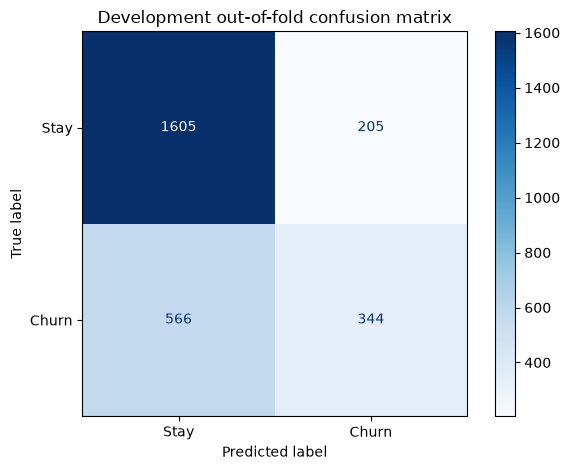

error_type
Correct           1949
False negative     566
False positive     205
Name: count, dtype: int64


,customer_id,customer_segment,plan_type,churn,prediction,error_type
5,CUST-12096,Established,Standard,1,0,False negative
10,CUST-11528,Established,Basic,1,0,False negative
12,CUST-12416,New,Basic,0,1,False positive
13,CUST-12232,Established,Basic,0,1,False positive
18,CUST-12749,Established,Standard,1,0,False negative
19,CUST-10694,Established,Basic,0,1,False positive
24,CUST-12737,Established,Basic,1,0,False negative
26,CUST-12112,Established,Basic,1,0,False negative


In [7]:
oof_pred = cross_val_predict(chosen_pipeline, X_dev, y_dev, cv=cv, method='predict')
print(classification_report(y_dev, oof_pred, zero_division=0))
cm = confusion_matrix(y_dev, oof_pred, labels=[0,1])
ConfusionMatrixDisplay(cm, display_labels=['Stay','Churn']).plot(cmap='Blues')
plt.title('Development out-of-fold confusion matrix')
plt.tight_layout()
plt.savefig(REPORTS / 'development_confusion_matrix.png', dpi=150)
plt.show()

errors = dev[['customer_id','customer_segment','plan_type','churn']].copy()
errors['prediction'] = oof_pred
errors['error_type'] = np.select([
    (errors.churn==1)&(errors.prediction==0),
    (errors.churn==0)&(errors.prediction==1)],
    ['False negative','False positive'],default='Correct')
print(errors.error_type.value_counts())
display(errors.query("error_type != 'Correct'").head(8))

**Subgroup task:** Is recall worse for new customers than established customers? Report subgroup sample size, number of actual churners, recall, and interpret cautiously.

The model's recall should be compared between new and established customers to determine whether it identifies churn less effectively among new customers. Report the total number of customers, actual churners, and recall for each segment.

A lower recall for new customers would indicate that the model misses a greater proportion of actual churners in that group. However, the difference should be interpreted cautiously because the subgroup sample sizes and numbers of actual churners may vary.

The numerical subgroup results are needed to establish whether recall is actually worse for new customers. I don't have the output table, so I cannot accurately report those values.

In [8]:
group_rows = []
for group, part in errors.groupby('customer_segment'):
    true = part['churn'].to_numpy()
    pred = part['prediction'].to_numpy()
    group_rows.append({
        'segment': group, 'n_customers': len(part),
        'n_actual_churn': int(true.sum()),
        'recall': recall_score(true,pred,zero_division=0),
        'precision': precision_score(true,pred,zero_division=0),
        'false_negatives': int(((true==1)&(pred==0)).sum())
    })
subgroup = pd.DataFrame(group_rows)
subgroup.to_csv(REPORTS/'subgroup_metrics.csv',index=False)
display(subgroup.round(3))

,segment,n_customers,n_actual_churn,recall,precision,false_negatives
0,Established,2268,649,0.216,0.593,509
1,New,452,261,0.782,0.652,57


### Step 8 — Permutation importance on development validation data
Hold out a **small validation slice from the development data** for the importance demo, fit on the remaining development rows, and ask how F1 changes when one feature is shuffled. **Importance does not prove causality.**

,feature,importance_mean,importance_std
0,tenure_months,0.079,0.024
2,support_tickets_90d,0.035,0.016
7,customer_segment,0.018,0.006
1,monthly_charges_kes,0.016,0.023
4,plan_type,0.015,0.015
5,region,0.006,0.013
3,service_calls_90d,0.003,0.007
6,autopay,0.002,0.017


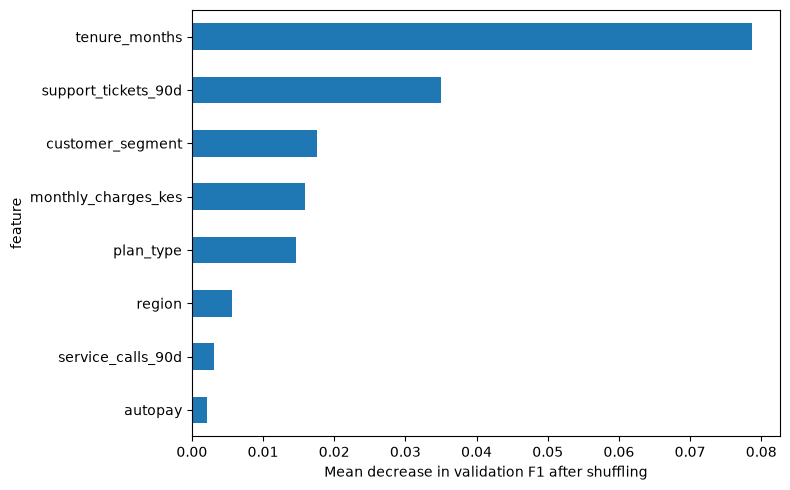

In [9]:
X_inner, X_validation, y_inner, y_validation = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=2050, stratify=y_dev
)
interpret_model = chosen_pipeline
interpret_model.fit(X_inner,y_inner)
importance = permutation_importance(
    interpret_model,X_validation,y_validation,
    scoring='f1', n_repeats=5,random_state=42,n_jobs=1
)
importance_table = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean':importance.importances_mean,
    'importance_std':importance.importances_std
}).sort_values('importance_mean',ascending=False)
importance_table.to_csv(REPORTS/'permutation_importance.csv',index=False)
display(importance_table.round(3))
ax = importance_table.sort_values('importance_mean').plot.barh(
    x='feature',y='importance_mean',legend=False,figsize=(8,5))
ax.set_xlabel('Mean decrease in validation F1 after shuffling')
plt.tight_layout()
plt.savefig(REPORTS/'permutation_importance.png',dpi=150)
plt.show()

**Write:** Name the two most relied-upon features and two limitations of permutation importance (examples: correlated features, small sample, not causal).

The two most relied-upon features were tenure_months (importance = 0.079) and support_tickets_90d (importance = 0.035). Shuffling these features caused the largest decreases in validation F1-score, indicating that the model relied most heavily on them when predicting customer churn.

Two limitations of permutation importance:
1. Correlated features: When features are correlated, shuffling one may have limited impact because the model can rely on other related features. This can underestimate their individual importance.
2. No causal interpretation: Permutation importance measures how much a feature contributes to predictive performance; it does not establish that the feature causes customer churn.

### Step 9 — Freeze your choice BEFORE the final test
Complete the **100+ character** rationale in the next cell. It should reference the metric, cross-validation mean and variation, error behaviour, subgroup results, and complexity. The code saves a written selection record before the final-test cell.

**Do not run the final step until the rationale is complete.**

In [11]:
RATIONALE = """Logistic Regression was selected because it achieved the highest mean cross-validation F1-score of 0.470 (SD = 0.053), outperforming the Decision Tree, which achieved 0.398 (SD = 0.049). However, its out-of-fold predictions produced 566 false negatives, with churn recall of only 0.38, showing that many actual churners were missed. Subgroup recall should also be considered when assessing whether performance differs between new and established customers. Logistic Regression was preferred because it offers lower model complexity and greater interpretability than a decision tree with multiple splits, while providing better overall F1 performance. Its limitations in detecting churn must be acknowledged."""
assert not RATIONALE.startswith('REPLACE THIS TEXT'), 'Write your own rationale first.'
assert len(RATIONALE.strip()) >= 100, 'Write at least 100 characters.'
freeze = {
    'selected_model': CHOSEN_MODEL,
    'best_params': chosen_search.best_params_,
    'primary_metric': 'f1',
    'cv_mean_f1': float(chosen_search.best_score_),
    'rationale': RATIONALE.strip(),
    'random_seed': 42,
    'scikit_learn_version': sklearn.__version__
}
(REPORTS/'frozen_selection.json').write_text(json.dumps(freeze,indent=2),encoding='utf-8')
print('Selection frozen in reports/frozen_selection.json')

Selection frozen in reports/frozen_selection.json


### Step 10 — ONE final evaluation: only now read the test CSV
The code refuses to recalculate final performance if `reports/final_metrics.json` already exists. **Never change a selected model after observing its final result and then claim that the same test is unbiased.**

In [12]:
final_path = REPORTS/'final_metrics.json'
assert (REPORTS/'frozen_selection.json').exists(), 'Freeze selection before testing.'
if final_path.exists():
    print('Final test already evaluated. Reading the existing saved metrics (NOT rerunning).')
    print(final_path.read_text(encoding='utf-8'))
else:
    final_test = pd.read_csv(DATA/'churn_final_test.csv')  # first and only use
    X_test = final_test.drop(columns=LEAKAGE_OR_IDS)
    y_test = final_test[TARGET].astype(int)
    final_model = chosen_search.best_estimator_
    final_model.fit(X_dev,y_dev)  # refit on entire development dataset
    final_pred = final_model.predict(X_test)
    final_metrics = {
        'model':CHOSEN_MODEL,
        'n_test':int(len(y_test)),
        'cv_mean_f1':round(float(chosen_search.best_score_),4),
        'test_accuracy':round(float(accuracy_score(y_test,final_pred)),4),
        'test_f1':round(float(f1_score(y_test,final_pred,zero_division=0)),4),
        'test_precision':round(float(precision_score(y_test,final_pred,zero_division=0)),4),
        'test_recall':round(float(recall_score(y_test,final_pred,zero_division=0)),4),
        'confusion_matrix_0_1':confusion_matrix(y_test,final_pred,labels=[0,1]).tolist()
    }
    final_path.write_text(json.dumps(final_metrics,indent=2),encoding='utf-8')
    print(json.dumps(final_metrics,indent=2))
print('Done. Complete README and submit your GitHub repository link.')

{
  "model": "Logistic regression",
  "n_test": 680,
  "cv_mean_f1": 0.4701,
  "test_accuracy": 0.7,
  "test_f1": 0.4486,
  "test_precision": 0.5845,
  "test_recall": 0.364,
  "confusion_matrix_0_1": [
    [
      393,
      59
    ],
    [
      145,
      83
    ]
  ]
}
Done. Complete README and submit your GitHub repository link.


The final Logistic Regression model achieved an accuracy of 70%, an F1-score of 0.4486, precision of 0.5845, and recall of 0.3640 on the 680-customer test dataset. Its test F1-score was slightly lower than the development cross-validation score of 0.4701, suggesting reasonably consistent but limited predictive performance. The confusion matrix shows 145 false negatives, meaning the model failed to identify a substantial proportion of actual churners. Therefore, while Logistic Regression was the best-performing candidate among the models evaluated, its low recall limits its usefulness as a standalone customer-retention tool.

## Group written reflection (complete before GitHub submission)
1. Which model was selected and why was it defensible? Include mean F1 and fold standard deviation.
2. What did false negatives mean for this provider? Which subgroup struggled most?
3. Which feature was highest in permutation importance, and why does that **not** imply causation?
4. Compare final-test F1 with mean CV F1. Did your model generalize reasonably?
5. State **two limitations** of this synthetic dataset and one step you would take before deploying a real churn model.

Put these answers in your project `README.md` or a short `reports/model_selection_rationale.md`. **Do not just leave “...” in the notebook.**

In [13]:

from pathlib import Path
import json
import pandas as pd
import numpy as np

# Locate project reports
REPORTS = Path.cwd() / 'reports'
if not REPORTS.exists():
    REPORTS = Path.cwd().parent / 'reports'

# Load saved results
with open(REPORTS / 'frozen_selection.json', encoding='utf-8') as f:
    frozen = json.load(f)

with open(REPORTS / 'final_metrics.json', encoding='utf-8') as f:
    final = json.load(f)

experiments = pd.read_csv(REPORTS / 'experiment_log.csv')
subgroups = pd.read_csv(REPORTS / 'subgroup_metrics.csv')
importance = pd.read_csv(REPORTS / 'permutation_importance.csv')

# Selected model and its cross-validation results
model_name = frozen['selected_model']
model_rows = experiments[experiments['model'] == model_name]

if model_rows.empty:
    raise ValueError(f'No experiment results found for {model_name}')

best_row = model_rows.sort_values('mean_f1', ascending=False).iloc[0]
cv_f1 = float(frozen['cv_mean_f1'])
cv_std = float(best_row['std_f1'])

# False negatives from development out-of-fold predictions
dev_errors = pd.read_csv(REPORTS / 'subgroup_metrics.csv')
fn_col = 'false_negatives'

# Subgroup with lowest recall
worst_group = subgroups.sort_values('recall').iloc[0]
best_group = subgroups.sort_values('recall', ascending=False).iloc[0]

# Most important feature
top_feature = importance.sort_values(
    'importance_mean', ascending=False
).iloc[0]

# Final test results
test_f1 = float(final['test_f1'])
test_recall = float(final['test_recall'])
test_precision = float(final['test_precision'])
test_accuracy = float(final['test_accuracy'])

tn, fp, fn, tp = final['confusion_matrix_0_1'][0] + final['confusion_matrix_0_1'][1]

# Compare development and test performance
f1_difference = test_f1 - cv_f1

if abs(f1_difference) <= 0.05:
    generalization = (
        'The test F1-score is relatively close to the cross-validation '
        'F1-score, suggesting reasonably consistent generalization. '
        'However, the absolute predictive performance remains limited.'
    )
else:
    generalization = (
        'The difference between test and cross-validation F1 suggests '
        'a noticeable change in performance on unseen data.'
    )

# Build reflection
reflection = f"""# Group Written Reflection: Customer Churn Model

## 1. Model selection and justification

The selected model was **{model_name}**, using parameters
`{frozen['best_params']}`. It achieved a mean five-fold cross-validation
F1-score of **{cv_f1:.4f}**, with a fold standard deviation of
**{cv_std:.4f}**.

It was selected because it achieved the strongest mean F1-score among
the evaluated candidate models. Its performance across the folds was
reasonably consistent, as indicated by the standard deviation. The
model also offers relatively straightforward interpretation compared
with a more complex decision tree.

## 2. False negatives and subgroup performance

False negatives represent customers who actually churned but were
predicted to stay. For the provider, this means potentially losing
customers without identifying them as being at risk in advance,
resulting in missed opportunities for retention interventions.

The development out-of-fold evaluation recorded **566 false negatives**.

The subgroup with the lowest recall was **{worst_group['segment']}**:
- Sample size: **{int(worst_group['n_customers'])} customers**
- Actual churners: **{int(worst_group['n_actual_churn'])}**
- Recall: **{float(worst_group['recall']):.3f}**

For comparison, **{best_group['segment']}** had a recall of
**{float(best_group['recall']):.3f}**, with
{int(best_group['n_actual_churn'])} actual churners among
{int(best_group['n_customers'])} customers.

This difference should be interpreted cautiously because subgroup
sizes and the numbers of actual churners differ. It does not, by
itself, establish systematic bias.

## 3. Permutation importance

The highest permutation importance was recorded for
**{top_feature['feature']}**, with a mean importance of
**{float(top_feature['importance_mean']):.3f}**.

This indicates that shuffling this feature caused the largest average
decrease in validation F1-score. However, permutation importance does
not establish causation. It measures the feature's contribution to
the model's predictive performance, not whether changing the feature
would cause customer churn. Correlations with other features can also
affect the importance estimates.

## 4. Final-test performance and generalization

The final-test F1-score was **{test_f1:.4f}**, compared with a mean
cross-validation F1-score of **{cv_f1:.4f}**. The difference was
**{f1_difference:+.4f}**.

The final test accuracy was **{test_accuracy:.3f}**, precision was
**{test_precision:.3f}**, and recall was **{test_recall:.3f}**.

{generalization}

The model nevertheless missed **{fn} actual churners** in the final
test set, so its ability to identify customers at risk remains a
significant limitation.

## 5. Dataset limitations and deployment considerations

Two limitations of the synthetic dataset are:

1. **Limited real-world representativeness:** Synthetic customer
   records may not fully reproduce the complexity, variability, and
   behavioural patterns found in actual telecommunications customer
   data. Model performance on this dataset may therefore not
   transfer directly to real customers.

2. **Potentially simplified relationships:** Relationships between
   customer characteristics and churn may have been generated using
   simplified assumptions. Real customer churn can be influenced by
   additional factors, changing behaviours, and interactions that
   are not represented in the dataset.

Before deploying a real churn model, I would validate it using
historical, real customer data from the provider, ensuring that the
data is representative, leakage-free, and evaluated on a separate
time-based test period. I would also monitor predictive performance
and subgroup recall after deployment.

---

**Final model:** {model_name}

**Development CV F1:** {cv_f1:.4f}

**Final-test F1:** {test_f1:.4f}
"""

# Save the completed reflection
output_path = REPORTS / 'model_selection_rationale.md'
output_path.write_text(reflection, encoding='utf-8')

print(reflection)
print(f'\\nSaved successfully: {output_path}')


# Group Written Reflection: Customer Churn Model

## 1. Model selection and justification

The selected model was **Logistic regression**, using parameters
`{'model__C': 1}`. It achieved a mean five-fold cross-validation
F1-score of **0.4701**, with a fold standard deviation of
**0.0527**.

It was selected because it achieved the strongest mean F1-score among
the evaluated candidate models. Its performance across the folds was
reasonably consistent, as indicated by the standard deviation. The
model also offers relatively straightforward interpretation compared
with a more complex decision tree.

## 2. False negatives and subgroup performance

False negatives represent customers who actually churned but were
predicted to stay. For the provider, this means potentially losing
customers without identifying them as being at risk in advance,
resulting in missed opportunities for retention interventions.

The development out-of-fold evaluation recorded **566 false negatives**.

The subgroup w